In [1]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegressionCV
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import pairwise_kernels, pairwise_distances
import numpy as np
from scipy.optimize import minimize
import seaborn as sns
%matplotlib inline
rng = np.random.default_rng(0)

In [2]:
def estimate_propensity(A, X, method='logistic'):
    #should run logistic regression on data and return a callable function f such that f(a,x)=p(A=a|X=x)
    n_features = X.shape[1]
    
    if method=='logistic':
        f=LogisticRegressionCV(
            cv=5, #5-fold cross-validation
            random_state=0,
            l1_ratios=(0,),
            scoring='accuracy',
            use_legacy_attributes=False
        )
        f.fit(X,np.ravel(A)) #fit the model
        #print(f.scores_)
    return f #can predict the log probabilities of each a in A for a given X=x by calling f.predict_log_proba(x)

In [3]:
def median_heuristic(X):
    d=X.shape[1]

    sigma=np.ones((d,))*1e-8
    for i in range(d):
        sigma[i]+=np.median(pairwise_distances(X[:,i].reshape(-1,1)))**2+1e-8

    sigma_iso = np.median(pairwise_distances(X))**2+1e-8

    sigma = sigma * sigma_iso / np.linalg.norm(sigma)

    return sigma

def rbf(X,sigma,Y=None):
    d = sigma.shape[0]

    assert d == X.shape[1]
    n = X.shape[0]

    
    if Y is None:
        kernel_matrix = np.ones((n,n))
        for i in range(d):
            kernel_matrix = np.multiply(kernel_matrix,pairwise_kernels(X[:,i].reshape(-1,1), metric="rbf", gamma=1.0 / (sigma[i])))

    else:
        n_2=Y.shape[0]
        kernel_matrix = np.ones((n,n_2))
        for i in range(d):
            kernel_matrix = np.multiply(kernel_matrix,pairwise_kernels(X[:,i].reshape(-1,1),Y[:,i].reshape(-1,1), metric="rbf", gamma=1.0 / (sigma[i])))
    return kernel_matrix

In [4]:
def DGP(n, ground_truth=False,a0=1):
    #data will be of form A | X | M | Y
    
    X=rng.uniform(size=(n,1))
    U=rng.uniform(size=(n,1))
    if ground_truth:
        A=a0*np.ones((n,1))
    else:
        A=rng.binomial(1,0.2*U+0.3*X+0.2)
    M=rng.normal(X+2*A,1,size=(n,1))
    Y=rng.normal(M+X+U,1,size=(n,1))
    return A,M,X,Y

In [5]:
def DGP_high_dim_X(n, ground_truth=False,a0=1, dim=3):
    D=np.hstack((np.zeros((dim,1)),np.vstack((np.eye(dim-1),np.zeros((dim-1,))))))
    cov = np.eye(dim)+0.5*D+0.5*D.T
    beta = np.pow(np.arange(1.,dim+1),-2)
    
    X=rng.multivariate_normal(np.zeros((dim,)),cov,size=n)
    U=rng.uniform(size=(n,))
    if ground_truth:
        A=a0*np.ones((n,))
    else:
        logit_matrix=-X@beta+U
        prob_matrix=np.pow(np.ones((n,))+np.exp(logit_matrix),-1)
        A=rng.binomial(1,prob_matrix)
    M=3*X@beta+2*np.multiply(A,X@beta)+5*np.multiply(A,np.pow(X,2)@beta)
    #M=np.pow(X@beta,2)+3*np.multiply(X@beta,A)+rng.normal(size=(n,))
    Y=M+X@np.pow(beta,2)+2*U+rng.normal(size=(n,))
    return A.reshape(-1,1),M.reshape(-1,1),X,Y.reshape(-1,1)

def DGP_high_dim_M(n, ground_truth=False,a0=1, dim=3):
    dim=3
    D=np.hstack((np.zeros((dim,1)),np.vstack((np.eye(dim-1),np.zeros((dim-1,))))))
    cov = np.eye(dim)+0.5*D+0.5*D.T
    beta = np.pow(np.arange(1.,dim+1),-2)
    
    X=rng.uniform(size=(n,))
    U=rng.uniform(size=(n,))
    if ground_truth:
        A=a0*np.ones((n,))
    else:
        A=rng.binomial(1,0.2*U+0.3*X+0.2)
    M=np.zeros((n,dim))
    for i in range(n):
        M[i,:]=rng.multivariate_normal(np.array([3*X[i],2*A[i]*X[i],5*A[i]*X[i]**2+3*A[i]]),cov,size=1)
        
    Y=3*X+5*M@beta+2*U+rng.normal(size=(n,))
    return A.reshape(-1,1),M,X.reshape(-1,1),Y.reshape(-1,1)

def DGP_high_dim_MX(n, ground_truth=False,a0=1, dim=3):
    D=np.hstack((np.zeros((dim,1)),np.vstack((np.eye(dim-1),np.zeros((dim-1,))))))
    cov = np.eye(dim)+0.5*D+0.5*D.T
    beta = np.pow(np.arange(1.,dim+1),-2)
    
    X=rng.multivariate_normal(np.ones((dim,)),cov,size=n)
    U=rng.uniform(size=(n))
    if ground_truth:
        A=a0*np.ones((n,))
    else:
        logit_matrix=-X@beta+U
        prob_matrix=np.pow(np.ones((n,))+np.exp(logit_matrix),-1)
        A=rng.binomial(1,prob_matrix)
    M=np.zeros((n,dim))
    for i in range(n):
        M[i,:]=rng.multivariate_normal((3*X[i,:]+2*A[i]*X[i,:]+5*A[i]*np.pow(X[i,:],2)),cov,size=1)
    Y=M@beta+X@np.pow(beta,2)+2*U+rng.normal(size=(n,))
    return A.reshape(-1,1),M,X,Y.reshape(-1,1)

In [6]:
def find_best_parameter(K_XX, Y, reg_grid=[1e1,1e0,1e-1,1e-2,1e-3,1e-4,1e-5,1e-6,1e-7,1e-8], num_cv=3):
    
    kr = GridSearchCV(
        KernelRidge(kernel='precomputed'),
        cv=num_cv,
        param_grid={"alpha": reg_grid},
        scoring='neg_root_mean_squared_error'
    )
    kr.fit(K_XX, Y)
    reg_param = kr.best_params_["alpha"]
    #print(kr.best_score_)
    #print(reg_param)
    """
    n=K_XX.shape[0]
    sigma=np.median(pairwise_distances(Y)) ** 2 + 1e-8
    K_YY=pairwise_kernels(Y, metric="rbf", gamma=1.0 / (sigma))
    assert K_XX.shape[1] == n
    
    res = minimize(
    lambda lmbda: np.trace(np.square(np.linalg.inv(np.diag(np.diag(np.eye(n)-K_XX@np.linalg.inv(K_XX+lmbda*np.eye(n)))))) @ (K_YY-2*K_XX@np.linalg.inv(K_XX+lmbda*np.eye(n))@K_YY+K_XX@np.linalg.inv(K_XX+lmbda*np.eye(n))@K_YY@np.linalg.inv(K_XX+lmbda*np.eye(n))@K_XX)),
    1.,
    method="BFGS",
    options={"gtol": 1e-6, "disp": False},
    )
    reg_param = res.x.ravel()[0]
    print(reg_param)"""
    return reg_param

In [7]:
def compute_EIF_a0(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te,a0=1,mean=True):
    n_tr=Y_tr.shape[0]
    n_te=Y_te.shape[0]
    #compute kernel bandwidths (median heuristic) and resulting kernels
    
    sigma_A=np.median(pairwise_distances(A_tr)) ** 2 + 1e-8
    K_AA = pairwise_kernels(A_tr, metric="rbf", gamma=1.0 / (sigma_A))

    
    sigma_M=median_heuristic(M_tr)
    K_MM = rbf(M_tr,sigma_M)
        
    sigma_X=median_heuristic(X_tr)
    K_XX = rbf(X_tr,sigma_X)
    """
    sigma_M=np.median(pairwise_distances(M_tr)) ** 2 + 1e-8
    K_MM = pairwise_kernels(M_tr, metric="rbf", gamma=1.0 / (sigma_M))

    sigma_X=np.median(pairwise_distances(X_tr)) ** 2 + 1e-8
    K_XX = pairwise_kernels(X_tr, metric="rbf", gamma=1.0 / (sigma_X))
    """
    
    #compute regularisations (grid search)
    K_AA_XX=np.multiply(K_AA,K_XX)
    K_AA_MM_XX=np.multiply(K_MM,K_AA_XX)
    lambda_y=find_best_parameter(K_AA_MM_XX,Y_tr)
    lambda_m=find_best_parameter(K_AA_XX,M_tr)

    #learn propensity and density ratio functions
    a_x =estimate_propensity(A_tr,X_tr)
    a_mx = estimate_propensity(A_tr,np.concatenate((X_tr,M_tr),axis=1))
    
    K_A1=pairwise_kernels(A_tr,np.array([[1.]]),metric="rbf", gamma=1.0 / (sigma_A))
    K_A0=pairwise_kernels(A_tr,np.array([[0.]]),metric="rbf", gamma=1.0 / (sigma_A))
    K_Aa0=pairwise_kernels(A_tr,a0*np.ones(A_te.shape),metric="rbf", gamma=1.0 / (sigma_A))

    #array of probabilities of each treatment a for each data point of shape (N,2)
    p_a_x_array=a_x.predict_proba(X_te)
    p_a_mx_array=a_mx.predict_proba(np.concatenate((X_te,M_te),axis=1))

    #array of the probability of treatment a0|x for each data point of shape (N,1)
    p_a0_x = a0*p_a_x_array[:,1] + (1-a0)*p_a_x_array[:,0]

    #array of the probability of observed treatment a|x for each data point of shape (N,1)
    p_a_x = np.multiply(A_te.ravel(),p_a_x_array[:,1]) + np.multiply((np.ones(A_te.ravel().shape)-A_te.ravel()),p_a_x_array[:,0])

    #array of the probability of treatment a0|m,x for each data point of shape (N,1)
    p_a0_mx = a0*p_a_mx_array[:,1] + (1-a0)*p_a_mx_array[:,0]

    #array of the probability of observed treatment a|m,x for each data point of shape (N,1)
    p_a_mx = np.multiply(A_te.ravel(),p_a_mx_array[:,1]) + np.multiply((np.ones(A_te.ravel().shape)-A_te.ravel()),p_a_mx_array[:,0])

    #array of density ratios p(m|a0,x)\p(m|a,x) for each data point of shape (N,1)
    dr_array = np.multiply(np.divide(p_a0_mx,p_a_mx),np.divide(p_a_x,p_a0_x))

    #tile this density ratio n times to form an NxN matrix where each row is the dr_array vector above
    dr_mat=np.tile(dr_array,(n_tr,1))

    #array for indicator term 1[a=a0]
    indicator_array = A_te.ravel() == a0*np.ones(A_te.ravel().shape)

    #matrix where each row is the array 1[a=a0]/p(a0|x)
    p_a0_x_reciprocal_mat=np.tile(np.divide(indicator_array,p_a0_x),(n_tr,1))

    #compute K_Xx matrix
    K_Xx=rbf(X_tr,sigma_X,X_te)
    #K_Xx = pairwise_kernels(X_tr, X_te, metric="rbf", gamma=1.0 / (sigma_X))
    #compute K_Mm matrix
    K_Mm=rbf(M_tr,sigma_M,M_te)
    #K_Mm = pairwise_kernels(M_tr, M_te, metric="rbf", gamma=1.0 / (sigma_M))
    #compute K_Aa matrix
    K_Aa=pairwise_kernels(A_tr,A_te,metric="rbf", gamma=1.0 / (sigma_A))
    #K_Aa_v2=np.outer(K_A1,A_te.ravel())+np.outer(K_A0,(np.ones(A_te.ravel().shape)-A_te.ravel()))
    

    #compute average K_Aa matrix given x
    K_Api=np.outer(K_A1,p_a_x_array[:,1])+np.outer(K_A0,p_a_x_array[:,0])
    #K_Api=K_AA@np.linalg.inv(K_XX+n_tr*lambda_a*np.eye(n_tr))@K_Xx

    R1=np.linalg.inv(K_AA_MM_XX+lambda_y*np.eye(n_tr))
    mu_m_a0x=K_MM@np.linalg.inv(K_AA_XX+lambda_m*np.eye(n_tr))@np.multiply(K_Aa0,K_Xx)
    K_Mm_Xx=np.multiply(K_Xx,K_Mm)
    
    first_term_mat=R1@np.multiply(dr_mat,np.multiply(K_Aa,K_Mm_Xx))
    first_term_v2=1/n_te * first_term_mat.sum(axis=1).reshape(-1,1)
    
    second_term_mat=second_term = R1@(np.multiply(p_a0_x_reciprocal_mat,(np.multiply(K_Api,K_Mm_Xx)-np.multiply(np.multiply(K_Api,mu_m_a0x),K_Xx))))
    second_term_v2=1/n_te * second_term_mat.sum(axis=1).reshape(-1,1)
    
    third_term_mat=R1@np.multiply(np.multiply(K_Aa,mu_m_a0x),K_Xx)
    third_term_v2=1/n_te * third_term_mat.sum(axis=1).reshape(-1,1)
    
    
    EIF_estimate=second_term_v2+third_term_v2-first_term_v2
    if mean:
        mean_estimate=np.dot(dr_array,Y_te)/n_te+Y_tr.T@(EIF_estimate)
        return mean_estimate.item()

    else:
        return dr_array,EIF_estimate

In [8]:
def compute_plugin_a0(A_tr,M_tr,X_tr,Y_tr,a0=1,mean=True):
    #compute kernel bandwidths (median heuristic) and resulting kernels
        
    n_tr=Y_tr.shape[0]
    #compute kernel bandwidths (median heuristic) and resulting kernels
    
    sigma_A=np.median(pairwise_distances(A_tr)) ** 2 + 1e-8
    K_AA = pairwise_kernels(A_tr, metric="rbf", gamma=1.0 / (sigma_A))

    
    sigma_M=median_heuristic(M_tr)
    K_MM = rbf(M_tr,sigma_M)
        
    sigma_X=median_heuristic(X_tr)
    K_XX = rbf(X_tr,sigma_X)
    """
    sigma_M=np.median(pairwise_distances(M_tr)) ** 2 + 1e-8
    K_MM = pairwise_kernels(M_tr, metric="rbf", gamma=1.0 / (sigma_M))

    sigma_X=np.median(pairwise_distances(X_tr)) ** 2 + 1e-8
    K_XX = pairwise_kernels(X_tr, metric="rbf", gamma=1.0 / (sigma_X))
    """

    #compute regularisations (grid search)
    K_AA_XX=np.multiply(K_AA,K_XX)
    K_AA_MM_XX=np.multiply(K_MM,K_AA_XX)
    lambda_y=find_best_parameter(K_AA_MM_XX,Y_tr)
    lambda_m=find_best_parameter(K_AA_XX,M_tr)
    #lambda_a=find_best_parameter(K_XX,A_tr)

    #learn propensity and density ratio functions
    a_x =estimate_propensity(A_tr,X_tr)
    a_mx = estimate_propensity(A_tr,np.concatenate((X_tr,M_tr),axis=1))
    
    K_A1=pairwise_kernels(A_tr,np.array([[1.]]),metric="rbf", gamma=1.0 / (sigma_A))
    K_A0=pairwise_kernels(A_tr,np.array([[0.]]),metric="rbf", gamma=1.0 / (sigma_A))
    K_Aa0=pairwise_kernels(A_tr,a0*np.ones(A_tr.shape),metric="rbf", gamma=1.0 / (sigma_A))

    p_a_x_array=a_x.predict_proba(X_tr)
    #p_a_mx_array=a_mx.predict_proba(np.concatenate((X_tr,M_tr),axis=1))

    #compute average K_Aa matrix given x
    K_Api=np.outer(K_A1,p_a_x_array[:,1])+np.outer(K_A0,p_a_x_array[:,0])
    #K_Api=K_AA@np.linalg.inv(K_XX+n_tr*lambda_a*np.eye(n_tr))@K_XX

    R1=np.linalg.inv(K_AA_MM_XX+lambda_y*np.eye(n_tr))
    mu_m_a0x=K_MM@np.linalg.inv(K_AA_XX+lambda_m*np.eye(n_tr))@np.multiply(K_Aa0,K_XX)
    

    second_term_mat=second_term = R1@np.multiply(np.multiply(K_Api,mu_m_a0x),K_XX)
    second_term_v2=1/n_tr * second_term_mat.sum(axis=1).reshape(-1,1)

    if mean:
        E_y_a0=Y_tr.T@second_term_v2
        return E_y_a0.item()
    else:
        return second_term_v2

In [9]:
def kernel_herding_EIF(Y_te,Y_tr,EIF_estimate,dr_array,n):
    sigma=np.median(pairwise_distances(Y_tr)) ** 2 + 1e-8

    #guess for location of sample
    y0 = rng.standard_normal()
    n_te=Y_te.shape[0]

    #first minimisation
    res = minimize(
        lambda y: -1./n_te*np.dot(pairwise_kernels(np.atleast_2d(y),Y_te,metric="rbf",gamma=1.0 / (sigma)).ravel(), dr_array)
        -(pairwise_kernels(np.atleast_2d(y),Y_tr,metric="rbf",gamma=1.0 / (sigma))@EIF_estimate).item(),
        y0,
        method="BFGS",
        options={"gtol": 1e-6, "disp": False},
    )
    y1 = res.x.ravel()[0]
    y_list = [y1]

    #sequential minmisation in kernel herding
    for t in range(2, n + 1):
        y_hist = np.array(y_list)
        res = minimize(
            lambda y: -1./n_te*np.dot(pairwise_kernels(np.atleast_2d(y),Y_te,metric="rbf",gamma=1.0 / (sigma)).ravel(), dr_array)
            -(pairwise_kernels(np.atleast_2d(y),Y_tr,metric="rbf",gamma=1.0 / (2 * sigma))@EIF_estimate).item()
            + np.mean(pairwise_kernels(y_hist.reshape(-1, 1),np.atleast_2d(y),metric="rbf",gamma=1.0 / (sigma))
            ),
            y0,
            method="BFGS",
            options={"gtol": 1e-6, "disp": False},
        )
        yt = res.x.ravel()[0]
        y_list.append(yt)
    return np.array(y_list)

def kernel_herding_plugin(Y_tr,plugin_estimate,n):
    sigma=np.median(pairwise_distances(Y_tr)) ** 2 + 1e-8

    #guess for initial point
    y0 = rng.standard_normal()

    #first minimisation
    res = minimize(
        lambda y: -np.dot(pairwise_kernels(Y_tr,np.atleast_2d(y),metric="rbf",gamma=1.0 / (sigma)).T, plugin_estimate),
        y0,
        method="BFGS",
        options={"gtol": 1e-6, "disp": False},
    )
    y1 = res.x.ravel()[0]
    y_list = [y1]

    #sequential minimisation for kernel herding
    for t in range(2, n + 1):
        y_hist = np.array(y_list)
        res = minimize(
            lambda y: -np.dot(pairwise_kernels(Y_tr,np.atleast_2d(y),metric="rbf",gamma=1.0 / (sigma)).T, plugin_estimate)
            + np.mean(pairwise_kernels(y_hist.reshape(-1, 1),np.atleast_2d(y),metric="rbf",gamma=1.0 / (sigma))
            ),
            y0,
            method="BFGS",
            options={"gtol": 1e-6, "disp": False},
        )
        yt = res.x.ravel()[0]
        y_list.append(yt)
    return np.array(y_list)

In [10]:
def make_plots(Y_obs, Y_true, Y_EIF_herded, Y_plugin_herded):
    plt.figure(figsize=(8, 5))
    #sns.histplot(Y_obs, color='g', kde=True, stat="density", label="Logged", alpha=0.5)
    sns.histplot(Y_true, color='b', kde=True, stat="density", label="Truth", alpha=0.5)
    sns.histplot(
        Y_EIF_herded,
        color="orange",
        kde=True,
        stat="density",
        label="Herded DR-CPME",
        alpha=0.5,
    )
    sns.histplot(
        Y_plugin_herded,
        color="green",
        kde=True,
        stat="density",
        label="Herded PI-CPME",
        alpha=0.5,
    )
    plt.xlim([Y_true.mean()-4*Y_true.std(), Y_true.mean()+4*Y_true.std()])
    plt.xlabel("Y")
    plt.ylabel("Density")
    plt.legend()
    plt.title("Counterfactual Outcome Distribution via Kernel Herding")
    plt.tight_layout()
    plt.show()
    plt.close()

In [11]:
def MMD(X,Y):
    #MMD based on samples X and Y from distributions P and Q
    """
    sigma=median_heuristic(Y)
    K_tr_tr=rbf(X,sigma)
    K_tr_te=rbf(X,sigma,Y)
    K_te_te=rbf(Y,sigma)
    """
    sigma=np.median(pairwise_distances(Y))**2+1e-8
    K_tr_tr = pairwise_kernels(X, metric="rbf", gamma=1.0 / (sigma))
    K_tr_te = pairwise_kernels(X,Y, metric="rbf", gamma=1.0 / (sigma))
    K_te_te = pairwise_kernels(Y, metric="rbf", gamma=1.0 / (sigma))
    first_term = K_tr_tr.mean()
    second_term = K_tr_te.mean() + K_tr_te.mean()
    third_term = K_te_te.mean()
    return first_term - second_term + third_term
    
def MMD_plugin(Y_tr,Y_truth,plugin_estimate):
    #MMD based on plugin mean embedding for distribution P and sample from distribution Q
    """
    sigma=median_heuristic(Y_tr)
    K_tr_tr=rbf(Y_tr,sigma)
    K_tr_te=rbf(Y_tr,sigma,Y_truth)
    K_te_te=rbf(Y_truth,sigma)"""
    sigma=np.median(pairwise_distances(Y_tr))**2+1e-8
    K_tr_tr = pairwise_kernels(Y_tr, metric="rbf", gamma=1.0 / (sigma))
    K_tr_te = pairwise_kernels(Y_tr,Y_truth, metric="rbf", gamma=1.0 / (sigma))
    K_te_te = pairwise_kernels(Y_truth, metric="rbf", gamma=1.0 / (sigma))
    first_term = (plugin_estimate.T @ K_tr_tr @ plugin_estimate)
    second_term = (plugin_estimate.T @ K_tr_te) + (K_tr_te.T @ plugin_estimate)
    third_term = (K_te_te)
    return first_term.mean() - second_term.mean() + third_term.mean()
    
def MMD_dr(Y_te,Y_tr,Y_truth,EIF_estimate,dr):
    #MMD based on doubly robust mean embedding for distribution P and sample from distribution Q
    dr = dr / dr.shape[0]
    """
    sigma=median_heuristic(Y_tr)
    K_tr_tr=rbf(Y_tr,sigma)
    K_tr_te=rbf(Y_tr,sigma,Y_te)
    K_te_te=rbf(Y_te,sigma)
    K_truth_truth=rbf(Y_truth,sigma)
    K_tr_truth=rbf(Y_tr,sigma,Y_truth)
    K_te_truth=rbf(Y_te,sigma,Y_truth)"""
    sigma=np.median(pairwise_distances(Y_tr))**2+1e-8
    K_tr_tr = pairwise_kernels(Y_tr, metric="rbf", gamma=1.0 / (sigma))
    K_tr_te = pairwise_kernels(Y_tr,Y_te, metric="rbf", gamma=1.0 / (sigma))
    K_te_te = pairwise_kernels(Y_te, metric="rbf", gamma=1.0 / (sigma))
    K_truth_truth=pairwise_kernels(Y_truth, metric="rbf", gamma=1.0 / (sigma))
    K_tr_truth=pairwise_kernels(Y_tr,Y_truth, metric="rbf", gamma=1.0 / (sigma))
    K_te_truth=pairwise_kernels(Y_te,Y_truth, metric="rbf", gamma=1.0 / (sigma))
    first_term = EIF_estimate.T @ K_tr_tr @ EIF_estimate + dr.T @ K_te_te @ dr + EIF_estimate.T @ K_tr_te @ dr + dr.T @ K_tr_te.T @ EIF_estimate
    second_term = dr.T @ K_te_truth + K_te_truth.T @ dr + EIF_estimate.T @ K_tr_truth + K_tr_truth.T @ EIF_estimate
    third_term = K_truth_truth
    return first_term.mean() - second_term.mean() + third_term.mean()

In [12]:
n=5000
treatment=1
dim=3
"""
A_tr,M_tr,X_tr,Y_tr = DGP_high_dim_M(n,dim=dim)
A_te,M_te,X_te,Y_te = DGP_high_dim_M(n,dim=dim)
A_truth,M_truth,X_truth,Y_truth = DGP_high_dim_M(n,ground_truth=True,a0=treatment,dim=dim)

"""

A_tr,M_tr,X_tr,Y_tr = DGP(n)
A_te,M_te,X_te,Y_te = DGP(n)
A_truth,M_truth,X_truth,Y_truth = DGP(n,ground_truth=True,a0=treatment)


In [13]:
with open('test.npy', 'rb') as f:
    A_tr=np.load(f)
    M_tr=np.load(f)
    X_tr=np.load(f)
    Y_tr=np.load(f)
    A_te=np.load(f)
    M_te=np.load(f)
    X_te=np.load(f)
    Y_te=np.load(f)
    A_truth=np.load(f)
    M_truth=np.load(f)
    X_truth=np.load(f)
    Y_truth=np.load(f)

In [14]:
EIF = compute_EIF_a0(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te,a0=treatment)
plugin = compute_plugin_a0(A_tr,M_tr,X_tr,Y_tr,a0=treatment)

print('DR: ',EIF)
print('PI: ',plugin)
print('truth: ',Y_truth.mean())

DR:  5.55357337915289
PI:  5.443986813744707
truth:  7.682818258261555


5.55357337915289
5.443986813744707
DR:
 mean =  12.882300295102796 
var =  7498.301388048934
PI:
 mean =  77.97147397367944 
var =  135784.89338416167
Truth:
 mean =  7.682818258261555 
var =  107.42524615827062


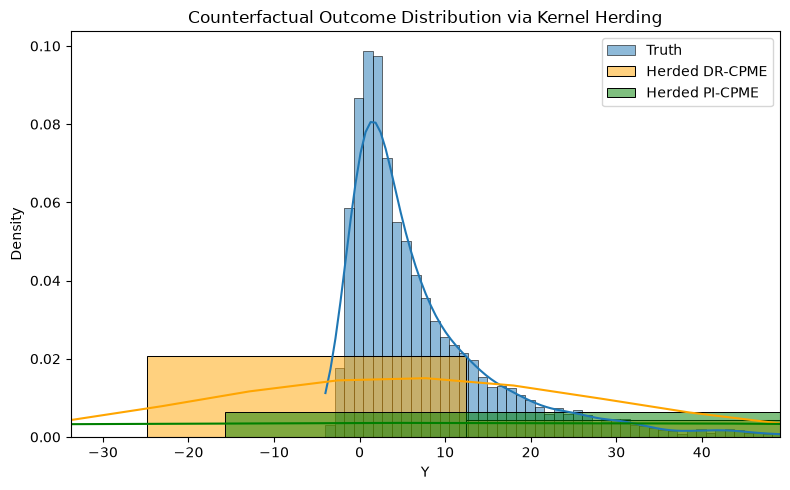

In [15]:
n=5000
treatment=1
dim=3
"""
A_tr,M_tr,X_tr,Y_tr = DGP_high_dim_MX(n,dim=dim)
A_te,M_te,X_te,Y_te = DGP_high_dim_MX(n,dim=dim)
A_truth,M_truth,X_truth,Y_truth = DGP_high_dim_MX(n,ground_truth=True,a0=treatment,dim=dim)

A_tr,M_tr,X_tr,Y_tr = DGP(n)
A_te,M_te,X_te,Y_te = DGP(n)
A_truth,M_truth,X_truth,Y_truth = DGP(n,ground_truth=True,a0=treatment)"""

dr,EIF = compute_EIF_a0(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te,a0=treatment,mean=False)
print((np.dot(Y_te.ravel(),dr)/Y_te.shape[0]+Y_tr.T@EIF).item())

plugin = compute_plugin_a0(A_tr,M_tr,X_tr,Y_tr,a0=treatment,mean=False)
print((Y_tr.T@plugin).item())

EIF_y_list=kernel_herding_EIF(Y_te,Y_tr,EIF,dr,750)
plugin_y_list=kernel_herding_plugin(Y_tr,plugin,750)


truth_y_list=Y_truth

print('DR:\n mean = ',np.mean(EIF_y_list),'\nvar = ',np.var(EIF_y_list))
print('PI:\n mean = ',np.mean(plugin_y_list),'\nvar = ',np.var(plugin_y_list))
print('Truth:\n mean = ',np.mean(truth_y_list),'\nvar = ',np.var(truth_y_list))
make_plots(Y_te,Y_truth,EIF_y_list,plugin_y_list)

In [16]:
#MMD between estimated distributions and true distribution
print('PI CKME: ',np.sqrt(MMD_plugin(Y_tr,Y_truth,plugin)))
print('DR CKME: ',np.sqrt(MMD_dr(Y_te,Y_tr,Y_truth,EIF,dr)))

print('Herded PI: ',np.sqrt(MMD(plugin_y_list.reshape(-1,1),Y_truth)))
print('Herded DR: ',np.sqrt(MMD(EIF_y_list.reshape(-1,1),Y_truth)))

PI CKME:  0.16057708003761134
DR CKME:  0.15109853465850984
Herded PI:  0.15182736958529983
Herded DR:  0.13065220124998703


20.253155027854376
19.89290616700647
DR:
 mean =  43.09522549903734 
var =  23930.093998589644
PI:
 mean =  74.76351114556762 
var =  87564.83455872067
Truth:
 mean =  22.32314767939452 
var =  394.8246323513447


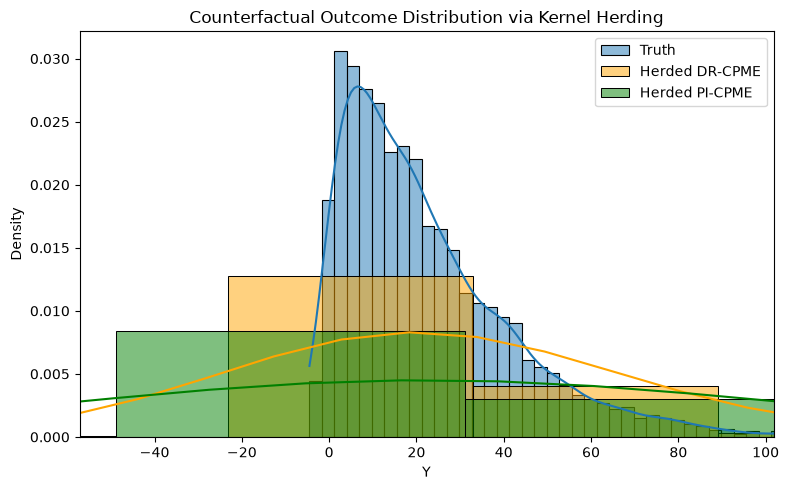

In [17]:
n=5000
treatment=1
dim=3

A_tr,M_tr,X_tr,Y_tr = DGP_high_dim_MX(n,dim=dim)
A_te,M_te,X_te,Y_te = DGP_high_dim_MX(n,dim=dim)
A_truth,M_truth,X_truth,Y_truth = DGP_high_dim_MX(n,ground_truth=True,a0=treatment,dim=dim)

dr,EIF = compute_EIF_a0(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te,a0=treatment,mean=False)
print((np.dot(Y_te.ravel(),dr)/Y_te.shape[0]+Y_tr.T@EIF).item())

plugin = compute_plugin_a0(A_tr,M_tr,X_tr,Y_tr,a0=treatment,mean=False)
print((Y_tr.T@plugin).item())

EIF_y_list=kernel_herding_EIF(Y_te,Y_tr,EIF,dr,750)
plugin_y_list=kernel_herding_plugin(Y_tr,plugin,750)


truth_y_list=Y_truth

print('DR:\n mean = ',np.mean(EIF_y_list),'\nvar = ',np.var(EIF_y_list))
print('PI:\n mean = ',np.mean(plugin_y_list),'\nvar = ',np.var(plugin_y_list))
print('Truth:\n mean = ',np.mean(truth_y_list),'\nvar = ',np.var(truth_y_list))
make_plots(Y_te,Y_truth,EIF_y_list,plugin_y_list)

In [18]:
#MMD between estimated distributions and true distribution
print('PI CKME: ',np.sqrt(MMD_plugin(Y_tr,Y_truth,plugin)))
print('DR CKME: ',np.sqrt(MMD_dr(Y_te,Y_tr,Y_truth,EIF,dr)))

print('Herded PI: ',np.sqrt(MMD(plugin_y_list.reshape(-1,1),Y_truth)))
print('Herded DR: ',np.sqrt(MMD(EIF_y_list.reshape(-1,1),Y_truth)))

PI CKME:  0.07662710660632183
DR CKME:  0.08000285400197403
Herded PI:  0.0705846103142677
Herded DR:  0.07009531417874953


0.4022
5.37988220861386
5.673231371426528
DR:
 mean =  13.91938102241605 
var =  3525.8251859441057
PI:
 mean =  105.03484635816957 
var =  137649.8671189611
Truth:
 mean =  7.807297235186388 
var =  108.47034082980542


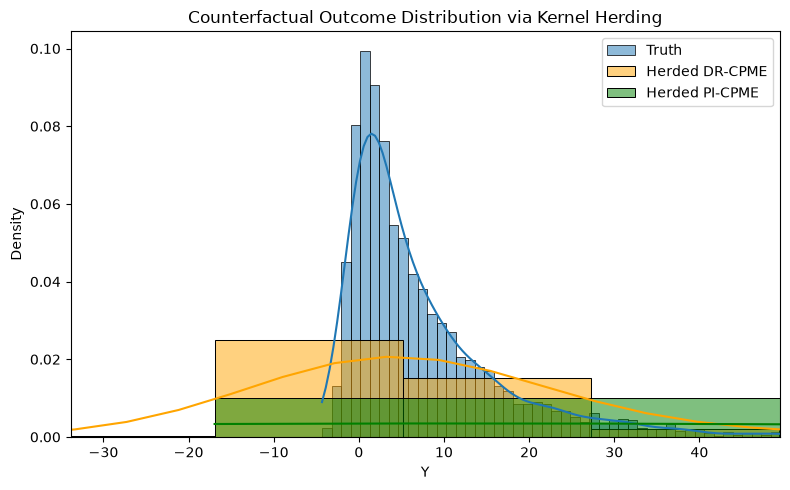

In [19]:
n=5000
treatment=1
dim=3

A_tr,M_tr,X_tr,Y_tr = DGP_high_dim_X(n,dim=dim)
A_te,M_te,X_te,Y_te = DGP_high_dim_X(n,dim=dim)
A_truth,M_truth,X_truth,Y_truth = DGP_high_dim_X(n,ground_truth=True,a0=treatment,dim=dim)

print(A_tr.mean())

dr,EIF = compute_EIF_a0(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te,a0=treatment,mean=False)
print((np.dot(Y_te.ravel(),dr)/Y_te.shape[0]+Y_tr.T@EIF).item())

plugin = compute_plugin_a0(A_tr,M_tr,X_tr,Y_tr,a0=treatment,mean=False)
print((Y_tr.T@plugin).item())

EIF_y_list=kernel_herding_EIF(Y_te,Y_tr,EIF,dr,750)
plugin_y_list=kernel_herding_plugin(Y_tr,plugin,750)


truth_y_list=Y_truth

print('DR:\n mean = ',np.mean(EIF_y_list),'\nvar = ',np.var(EIF_y_list))
print('PI:\n mean = ',np.mean(plugin_y_list),'\nvar = ',np.var(plugin_y_list))
print('Truth:\n mean = ',np.mean(truth_y_list),'\nvar = ',np.var(truth_y_list))
make_plots(Y_te,Y_truth,EIF_y_list,plugin_y_list)

In [20]:
#MMD between estimated distributions and true distribution
print('PI CKME: ',np.sqrt(MMD_plugin(Y_tr,Y_truth,plugin)))
print('DR CKME: ',np.sqrt(MMD_dr(Y_te,Y_tr,Y_truth,EIF,dr)))

print('Herded PI: ',np.sqrt(MMD(plugin_y_list.reshape(-1,1),Y_truth)))
print('Herded DR: ',np.sqrt(MMD(EIF_y_list.reshape(-1,1),Y_truth)))

PI CKME:  0.16984668466194916
DR CKME:  0.15498210734949786
Herded PI:  0.15820590710203472
Herded DR:  0.12081415451815064


In [21]:
with open('test.npy', 'wb') as f:
    np.save(f, A_tr)
    np.save(f, M_tr)
    np.save(f, X_tr)
    np.save(f, Y_tr)
    np.save(f, A_te)
    np.save(f, M_te)
    np.save(f, X_te)
    np.save(f, Y_te)
    np.save(f, A_truth)
    np.save(f, M_truth)
    np.save(f, X_truth)
    np.save(f, Y_truth)

10.814140944515563
10.982368607133969
DR:
 mean =  12.907582188546272 
var =  811.6235883485061
PI:
 mean =  12.569255828755692 
var =  40344.51170400257
Truth:
 mean =  13.68769260558865 
var =  81.99329197514702


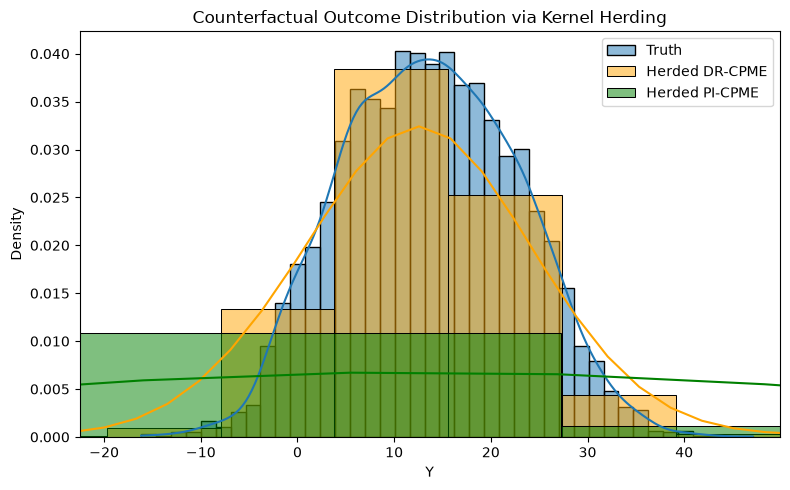

In [22]:
n=5000
treatment=1
dim=3

A_tr,M_tr,X_tr,Y_tr = DGP_high_dim_M(n,dim=dim)
A_te,M_te,X_te,Y_te = DGP_high_dim_M(n,dim=dim)
A_truth,M_truth,X_truth,Y_truth = DGP_high_dim_M(n,ground_truth=True,a0=treatment,dim=dim)

dr,EIF = compute_EIF_a0(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te,a0=treatment,mean=False)
print((np.dot(Y_te.ravel(),dr)/Y_te.shape[0]+Y_tr.T@EIF).item())

plugin = compute_plugin_a0(A_tr,M_tr,X_tr,Y_tr,a0=treatment,mean=False)
print((Y_tr.T@plugin).item())

EIF_y_list=kernel_herding_EIF(Y_te,Y_tr,EIF,dr,750)
plugin_y_list=kernel_herding_plugin(Y_tr,plugin,750)


truth_y_list=Y_truth

print('DR:\n mean = ',np.mean(EIF_y_list),'\nvar = ',np.var(EIF_y_list))
print('PI:\n mean = ',np.mean(plugin_y_list),'\nvar = ',np.var(plugin_y_list))
print('Truth:\n mean = ',np.mean(truth_y_list),'\nvar = ',np.var(truth_y_list))
make_plots(Y_te,Y_truth,EIF_y_list,plugin_y_list)

In [23]:
#MMD between estimated distributions and true distribution
print('PI CKME: ',np.sqrt(MMD_plugin(Y_tr,Y_truth,plugin)))
print('DR CKME: ',np.sqrt(MMD_dr(Y_te,Y_tr,Y_truth,EIF,dr)))

print('Herded PI: ',np.sqrt(MMD(plugin_y_list.reshape(-1,1),Y_truth)))
print('Herded DR: ',np.sqrt(MMD(EIF_y_list.reshape(-1,1),Y_truth)))

PI CKME:  0.1016346089042671
DR CKME:  0.10667479240018689
Herded PI:  0.09548085214518394
Herded DR:  0.0715777672339788


In [24]:
#save results

with open('test.npy', 'wb') as f:
    np.save(f, dr)
    np.save(f, EIF)
    np.save(f, Y_tr)
    np.save(f, Y_te)
    np.save(f, Y_truth)
with open('plugin_test.npy', 'wb') as f:
    np.save(f, np.zeros(plugin.shape))
    np.save(f,plugin)
    np.save(f,Y_tr)
    np.save(f,np.zeros(Y_tr.shape))
    np.save(f,Y_truth)

In [25]:
from scipy.stats import norm

def KTE(A_1,M_1,X_1,Y_1,A_2,M_2,X_2,Y_2):
    n_1=Y_1.shape[0]
    n_2=Y_2.shape[0]
    assert n_1==n_2
    #train a doubly robust estimator using 1 as 'tr' and 2 as 'te' for both a0=1 and a0=0
    dr_11,eif_11=compute_EIF_a0(A_1,M_1,X_1,Y_1,A_2,M_2,X_2,Y_2,a0=1,mean=False)
    dr_10,eif_10=compute_EIF_a0(A_1,M_1,X_1,Y_1,A_2,M_2,X_2,Y_2,a0=0,mean=False)
    dr_1_diff=(dr_11-dr_10)/dr_11.shape[0]
    eif_1_diff=eif_11-eif_10
    dr_1_mat=np.tile(dr_1_diff,(n_2,1))
    eif_1_mat=np.tile(eif_1_diff.ravel(),(n_1,1))

    #train a doubly robust estimator using 2 as 'tr' and 1 as 'te' for both a0=1 and a0=0
    dr_21,eif_21=compute_EIF_a0(A_2,M_2,X_2,Y_2,A_1,M_1,X_1,Y_1,a0=1,mean=False)
    dr_20,eif_20=compute_EIF_a0(A_2,M_2,X_2,Y_2,A_1,M_1,X_1,Y_1,a0=0,mean=False)
    dr_2_diff=(dr_21-dr_20)/dr_21.shape[0]
    eif_2_diff=eif_21-eif_20
    dr_2_mat=np.tile(dr_2_diff,(n_1,1))
    eif_2_mat=np.tile(eif_2_diff.ravel(),(n_2,1))
    
    #compute inner product
    sigma=median_heuristic(Y_1)
    K_11=rbf(Y_1,sigma)
    K_22=rbf(Y_2,sigma)
    K_12=rbf(Y_1,sigma,Y_2)
    K_21=K_12.T

    term_1=np.multiply(dr_1_mat,np.multiply(K_21,dr_2_mat.T)) 
    term_2=np.multiply(eif_1_mat,np.multiply(K_12,eif_2_mat.T)) 
    term_3=np.multiply(eif_1_mat,np.multiply(K_11,dr_2_mat.T))
    term_4=np.multiply(dr_1_mat,np.multiply(K_22,eif_2_mat.T))

    f_mat=term_1+term_2+term_3+term_4
    f_vec=f_mat.mean(axis=1)
    s=f_vec.std()
    f=f_vec.mean()
    T=np.sqrt(n_1)*f/s
    
        
    #inverse Gaussian cdf for test statistic
    p_val=1-norm.cdf(T)
    return p_val

In [26]:
n=1000
A_tr,M_tr,X_tr,Y_tr = DGP(n)
A_te,M_te,X_te,Y_te = DGP(n)
print(KTE(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te))

0.0


In [27]:
def DGP_2(n, ground_truth=False,a0=1):
    #data will be of form A | X | M | Y
    
    X=rng.uniform(size=(n,1))
    U=rng.uniform(size=(n,1))
    if ground_truth:
        A=a0*np.ones((n,1))
    else:
        A=rng.binomial(1,0.2*U+0.3*X+0.2)
    M=rng.normal(2*X,1,size=(n,1))
    Y=rng.normal(M+X+U,1,size=(n,1))
    return A,M,X,Y
    
def DGP_high_dim_X_2(n, ground_truth=False,a0=1, dim=3):
    D=np.hstack((np.zeros((dim,1)),np.vstack((np.eye(dim-1),np.zeros((dim-1,))))))
    cov = np.eye(dim)+0.5*D+0.5*D.T
    beta = np.pow(np.arange(1.,dim+1),-2)
    
    X=rng.multivariate_normal(np.ones((dim,)),cov,size=n)
    U=np.zeros((n,))#rng.uniform(size=(n,))
    if ground_truth:
        A=a0*np.ones((n,))
    else:
        logit_matrix=-X@beta+U
        prob_matrix=np.pow(np.ones((n,))+np.exp(logit_matrix),-1)
        A=rng.binomial(1,prob_matrix)
    M=X@np.ones((dim,))+0.1*rng.normal(size=(n,))
    Y=M+X@np.pow(beta,2)+2*U+rng.normal(size=(n,))
    return A.reshape(-1,1),M.reshape(-1,1),X,Y.reshape(-1,1)

def DGP_high_dim_M_2(n, ground_truth=False,a0=1, dim=3):
    dim=3
    D=np.hstack((np.zeros((dim,1)),np.vstack((np.eye(dim-1),np.zeros((dim-1,))))))
    cov = np.eye(dim)+0.5*D+0.5*D.T
    beta = np.pow(np.arange(1.,dim+1),-2)
    
    X=rng.uniform(size=(n,))
    U=rng.uniform(size=(n,))
    if ground_truth:
        A=a0*np.ones((n,))
    else:
        A=rng.binomial(1,0.2*U+0.3*X+0.2)
    M=np.zeros((n,dim))
    for i in range(n):
        M[i,:]=rng.multivariate_normal(np.array([3*X[i],2*X[i],5*X[i]**2+3]),cov,size=1)
        
    Y=3*X+5*M@beta+2*U+rng.normal(size=(n,))
    return A.reshape(-1,1),M,X.reshape(-1,1),Y.reshape(-1,1)

def DGP_high_dim_MX_2(n, ground_truth=False,a0=1, dim=3):
    D=np.hstack((np.zeros((dim,1)),np.vstack((np.eye(dim-1),np.zeros((dim-1,))))))
    cov = np.eye(dim)+0.5*D+0.5*D.T
    beta = np.pow(np.arange(1.,dim+1),-2)
    
    X=rng.multivariate_normal(np.ones((dim,)),cov,size=n)
    U=rng.uniform(size=(n))
    if ground_truth:
        A=a0*np.ones((n,))
    else:
        logit_matrix=-X@beta+U
        prob_matrix=np.pow(np.ones((n,))+np.exp(logit_matrix),-1)
        A=rng.binomial(1,prob_matrix)
    M=np.zeros((n,dim))
    for i in range(n):
        M[i,:]=rng.multivariate_normal((3*X[i,:]+2*X[i,:]+5*np.pow(X[i,:],2)),cov,size=1)
    Y=M@beta+X@np.pow(beta,2)+2*U+rng.normal(size=(n,))
    return A.reshape(-1,1),M,X,Y.reshape(-1,1)

In [28]:
n=1000
A_tr,M_tr,X_tr,Y_tr = DGP_2(n)
A_te,M_te,X_te,Y_te = DGP_2(n)
print(KTE(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te))

0.9995276322130583
